# Matrices de transición y roll rates: de una matriz única a un pronóstico creíble

**Perfil:** Riesgo de crédito (productos)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿Qué tan confiable es la PD a 12 meses que sale de elevar a una potencia una matriz de transición estimada? ¿Qué rompe esa estimación (poca muestra, heterogeneidad, ciclo) y qué corrección ayuda de verdad?

## Recorrido

1. Panel sintético de 60.000 cuentas con dos segmentos, un ciclo macro y memoria de segundo orden.
2. **Versión 1:** una matriz homogénea estimada por máxima verosimilitud.
3. **Diagnóstico:** incertidumbre (bootstrap y su cobertura), heterogeneidad y propiedad de Markov.
4. **Versión 2:** matrices por segmento. **Versión 3:** ventana reciente con suavizado hacia el promedio.
5. **Versión 4:** ajuste por un indicador macro observado.
6. Pronóstico fuera de tiempo frente a la realidad simulada, pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.stats import chi2_contingency
from numpy.linalg import matrix_power

## 2. El mundo simulado

Cinco estados: `al_dia`, `mora_30`, `mora_60`, `mora_90` y `default` (absorbente). Lo que el generador contiene, y que un modelo ingenuo ignora:

1. **Dos segmentos** con riesgos distintos (70 % *prime*, 30 % *subprime*).
2. **Ciclo macro:** un choque que multiplica las probabilidades de empeorar, con una **deterioración sostenida en los meses 24–35**, fuera de la ventana de entrenamiento (meses 0–23).
3. **Memoria:** una cuenta que *regresa* de `mora_60` a `mora_30` tiene menor probabilidad de volver a empeorar. Eso viola la propiedad de Markov.

In [2]:
ESTADOS = ["al_dia", "mora_30", "mora_60", "mora_90", "default"]
K = 5
BASE = {
    "prime": np.array([[0.965, 0.030, 0.000, 0.000, 0.005],
                       [0.400, 0.380, 0.220, 0.000, 0.000],
                       [0.150, 0.120, 0.330, 0.400, 0.000],
                       [0.050, 0.000, 0.100, 0.450, 0.400],
                       [0.000, 0.000, 0.000, 0.000, 1.000]]),
    "subprime": np.array([[0.900, 0.080, 0.000, 0.000, 0.020],
                          [0.300, 0.370, 0.330, 0.000, 0.000],
                          [0.100, 0.100, 0.300, 0.500, 0.000],
                          [0.030, 0.000, 0.070, 0.400, 0.500],
                          [0.000, 0.000, 0.000, 0.000, 1.000]]),
}
for P in BASE.values():
    assert np.allclose(P.sum(axis=1), 1)


def escalar(P, f):
    # multiplica por f las probabilidades de empeorar; el resto de la fila (quedarse o mejorar) se
    # reescala proporcionalmente para que la fila siga sumando 1 (con un tope para no pasarse de 1)
    Q = P.copy()
    for i in range(K - 1):
        peor = min(P[i, i + 1:].sum() * f, 0.98)
        Q[i, i + 1:] = P[i, i + 1:] * (peor / P[i, i + 1:].sum())
        resto = P[i, :i + 1]
        Q[i, :i + 1] = resto * ((1 - peor) / resto.sum())
    assert np.allclose(Q.sum(axis=1), 1) and (Q >= 0).all()
    return Q


T_TOTAL, T_TRAIN = 36, 24
meses = np.arange(T_TOTAL)
choque = 0.25 * np.sin(2 * np.pi * meses / 24) + 0.60 * np.clip((meses - 24) / 12, 0, None)   # el ciclo verdadero
macro_obs = choque + np.random.default_rng(5).normal(0, 0.05, T_TOTAL)                       # lo que el analista observa
print("choque en meses 0, 12, 24, 30, 35:", choque[[0, 12, 24, 30, 35]].round(2))

choque en meses 0, 12, 24, 30, 35: [ 0.    0.   -0.    0.55  0.61]


In [3]:
def simular_panel(n=60_000, seed=SEED):
    rng = np.random.default_rng(seed)
    seg = (rng.random(n) < 0.30).astype(int)                       # 1 = subprime
    estado = rng.choice(K - 1, n, p=[0.85, 0.08, 0.04, 0.03])
    previo = np.zeros(n, dtype=int)
    panel = np.zeros((n, T_TOTAL + 1), dtype=np.int8)
    panel[:, 0] = estado
    for t in range(T_TOTAL):
        prob = np.empty((n, K))
        for s_id, nombre in enumerate(("prime", "subprime")):
            P = escalar(BASE[nombre], 1 + choque[t])
            m = seg == s_id
            prob[m] = P[estado[m]]
        memoria = (estado == 1) & (previo == 2)                    # vienen de curar desde mora_60
        if memoria.any():
            p = prob[memoria]
            p[:, 2:] *= 0.5
            p[:, 1] = 1 - p[:, [0, 2, 3, 4]].sum(axis=1)
            prob[memoria] = p
        cum = prob.cumsum(axis=1)
        u = rng.random(n)
        nuevo = np.minimum((u[:, None] > cum).sum(axis=1), K - 1)
        previo = estado.copy()
        estado = nuevo
        panel[:, t + 1] = estado
    return panel, seg


panel, seg = simular_panel()
print(panel.shape, "| default al mes 36:", f"{(panel[:, -1] == 4).mean():.2%}", "| subprime:", f"{seg.mean():.1%}")

(60000, 37) | default al mes 36: 53.94% | subprime: 30.3%


## 3. Versión 1: una matriz homogénea por máxima verosimilitud

El estimador de máxima verosimilitud de una cadena de Markov es la **fila normalizada de los conteos de transición**: $\hat p_{ij}=n_{ij}/n_{i\cdot}$. La PD a 12 meses de una cuenta al día es la entrada $(0,\text{default})$ de $\hat P^{12}$.

In [4]:
def conteos(panel, mascara=None, t0=0, t1=T_TOTAL):
    # conteos de transicion de t a t+1 para t en [t0, t1)
    n = np.zeros((K, K))
    for t in range(t0, t1):
        a = panel[:, t] if mascara is None else panel[mascara, t]
        b = panel[:, t + 1] if mascara is None else panel[mascara, t + 1]
        np.add.at(n, (a, b), 1)
    return n


def mle(n):
    fila = n.sum(axis=1, keepdims=True)
    return np.divide(n, fila, out=np.zeros_like(n), where=fila > 0)


def pd12(P):
    return matrix_power(P, 12)[0, 4]


n_train = conteos(panel, t0=0, t1=T_TRAIN)
P1 = mle(n_train)
print(pd.DataFrame(P1, index=ESTADOS, columns=ESTADOS).round(3).to_string())
print(f"\nPD a 12 meses de una cuenta al dia (v1): {pd12(P1):.4f}")
print("Observaciones por fila de estado:", n_train.sum(axis=1).astype(int).tolist())

         al_dia  mora_30  mora_60  mora_90  default
al_dia   0.9500   0.0410   0.0000   0.0000   0.0080
mora_30  0.3530   0.3770   0.2700   0.0000   0.0000
mora_60  0.1180   0.1040   0.3070   0.4710   0.0000
mora_90  0.0390   0.0000   0.0820   0.4010   0.4780
default  0.0000   0.0000   0.0000   0.0000   1.0000

PD a 12 meses de una cuenta al dia (v1): 0.1548
Observaciones por fila de estado: [980358, 75179, 35181, 29658, 319624]


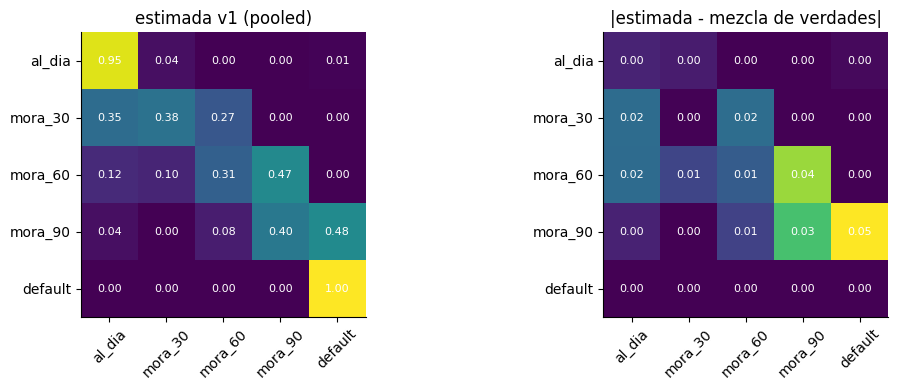

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
P_media_verdad = 0.7 * escalar(BASE["prime"], 1) + 0.3 * escalar(BASE["subprime"], 1)
for a, (M, titulo) in zip(ax, ((P1, "estimada v1 (pooled)"), (np.abs(P1 - P_media_verdad), "|estimada - mezcla de verdades|"))):
    im = a.imshow(M, cmap="viridis"); a.set_xticks(range(K)); a.set_yticks(range(K))
    a.set_xticklabels(ESTADOS, rotation=45); a.set_yticklabels(ESTADOS); a.set_title(titulo); a.grid(False)
    for i in range(K):
        for j in range(K): a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Diagnóstico

### 4.1 Incertidumbre: ¿cuánto confiar en un solo número?

Se remuestrea **cuentas completas** (no transiciones sueltas, que ignoraría la dependencia dentro de una cuenta) y se recalcula la PD a 12 meses.

In [6]:
def conteos_por_cuenta(panel, t0, t1):
    n = panel.shape[0]
    out = np.zeros((n, K, K), dtype=np.int16)
    idx = np.arange(n)
    for t in range(t0, t1):
        np.add.at(out, (idx, panel[:, t], panel[:, t + 1]), 1)
    return out


def bootstrap_pd12(cuentas, B=300, seed=0):
    rng = np.random.default_rng(seed)
    n = cuentas.shape[0]
    vals = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, n)
        vals[b] = pd12(mle(cuentas[idx].sum(axis=0).astype(float)))
    return vals

cuentas_train = conteos_por_cuenta(panel, 0, T_TRAIN)
bs = bootstrap_pd12(cuentas_train)
lo, hi = np.percentile(bs, [2.5, 97.5])
print(f"PD12 v1 = {pd12(P1):.4f}  IC95% bootstrap = [{lo:.4f}, {hi:.4f}]  (ancho relativo {(hi - lo) / pd12(P1):.1%})")

PD12 v1 = 0.1548  IC95% bootstrap = [0.1527, 0.1570]  (ancho relativo 2.8%)


Un intervalo estrecho no significa que el modelo sea correcto: **solo mide el error de muestreo bajo el supuesto de que el modelo es verdadero**. Antes de confiar en él, hay que comprobar que ese intervalo *cubre* de verdad el valor correcto cuando el modelo sí es cierto.

### 4.2 ¿El intervalo cubre? Experimento de cobertura con un mundo homogéneo

Se simula un mundo **homogéneo y de Markov** (donde v1 es correcto por construcción), con una muestra pequeña, y se mide con qué frecuencia el IC del 95 % contiene la PD verdadera.

In [7]:
def simular_homogeneo(P, n, T, rng):
    estado = rng.choice(K - 1, n, p=[0.85, 0.08, 0.04, 0.03])
    pan = np.zeros((n, T + 1), dtype=np.int8); pan[:, 0] = estado
    cum = P.cumsum(axis=1)
    for t in range(T):
        u = rng.random(n)
        estado = np.minimum((u[:, None] > cum[estado]).sum(axis=1), K - 1)
        pan[:, t + 1] = estado
    return pan


P_ver = 0.7 * escalar(BASE["prime"], 1) + 0.3 * escalar(BASE["subprime"], 1)
pd12_ver = pd12(P_ver)
rng_cov = np.random.default_rng(11)
cubre, anchos = [], []
for rep in range(60):
    pan = simular_homogeneo(P_ver, n=1500, T=12, rng=rng_cov)
    cuentas = conteos_por_cuenta(pan, 0, 12)
    b = bootstrap_pd12(cuentas, B=150, seed=rep)
    l, h = np.percentile(b, [2.5, 97.5])
    cubre.append(l <= pd12_ver <= h); anchos.append(h - l)
cobertura = float(np.mean(cubre))
print(f"PD12 verdadera = {pd12_ver:.4f}")
print(f"Cobertura empirica del IC95% en 60 replicas: {cobertura:.1%} (ancho medio {np.mean(anchos):.4f})")

PD12 verdadera = 0.1588
Cobertura empirica del IC95% en 60 replicas: 98.3% (ancho medio 0.0341)


In [8]:
print("Lectura:")
print(f"  Cuando el modelo ES correcto, el IC95% cubre {cobertura:.0%} de las veces: el procedimiento de incertidumbre funciona.")
print("  El intervalo del panel real (seccion 4.1) mide solo ruido de muestreo; no dice nada sobre sesgo por heterogeneidad ni por ciclo.")

Lectura:
  Cuando el modelo ES correcto, el IC95% cubre 98% de las veces: el procedimiento de incertidumbre funciona.
  El intervalo del panel real (seccion 4.1) mide solo ruido de muestreo; no dice nada sobre sesgo por heterogeneidad ni por ciclo.


### 4.3 ¿Se cumple que la matriz es la misma para todos? Prueba de homogeneidad

Se compara, fila por fila, la distribución de destinos entre segmentos con una prueba $\chi^2$ de independencia. Si los segmentos fueran iguales, los p-valores no serían significativos.

In [9]:
n_prime = conteos(panel, mascara=(seg == 0), t0=0, t1=T_TRAIN)
n_sub = conteos(panel, mascara=(seg == 1), t0=0, t1=T_TRAIN)
filas = []
for i in range(K - 1):
    tabla = np.vstack([n_prime[i], n_sub[i]])
    tabla = tabla[:, tabla.sum(axis=0) > 0]
    chi, p, gl, _ = chi2_contingency(tabla)
    filas.append({"estado_origen": ESTADOS[i], "chi2": chi, "gl": gl, "p_valor": p})
het = pd.DataFrame(filas).set_index("estado_origen")
het

,chi2,gl,p_valor
estado_origen,,,
al_dia,"16,730.4766",2,0.0000
mora_30,"1,447.9021",2,0.0000
mora_60,546.8560,3,0.0000
mora_90,439.6410,3,0.0000


### 4.4 ¿Se cumple la propiedad de Markov? Memoria de segundo orden

In [10]:
# desde mora_30, ¿importa de donde vino la cuenta? (0 = al dia, 2 = mora_60)
a_, b_, c_ = [], [], []
for t in range(1, T_TRAIN):
    m = panel[:, t] == 1
    a_.append(panel[m, t - 1]); b_.append(panel[m, t + 1])
prev = np.concatenate(a_); sig = np.concatenate(b_)
tabla = np.array([[((prev == p_) & (sig == s_)).sum() for s_ in range(K)] for p_ in (0, 2)])
tabla = tabla[:, tabla.sum(axis=0) > 0]
chi, p_mem, gl, _ = chi2_contingency(tabla)
emp = tabla / tabla.sum(axis=1, keepdims=True)
print("Destino desde mora_30 segun el estado previo (columnas con datos):")
print(pd.DataFrame(emp, index=["viene de al_dia", "viene de mora_60"]).round(3).to_string())
print(f"chi2={chi:.1f}, p-valor={p_mem:.2e}")

Destino desde mora_30 segun el estado previo (columnas con datos):
                      0      1      2
viene de al_dia  0.3510 0.3680 0.2810
viene de mora_60 0.3470 0.5150 0.1380
chi2=435.7, p-valor=2.51e-95


In [11]:
print("Lectura:")
print(f"  Homogeneidad entre segmentos: p-valores de {het['p_valor'].min():.1e} a {het['p_valor'].max():.1e} -> {'se rechaza' if (het['p_valor'] < 0.01).all() else 'no se rechaza en todas las filas'}.")
print(f"  Propiedad de Markov: p-valor {p_mem:.1e} -> {'hay memoria: las cuentas que curan desde mora_60 empeoran menos' if p_mem < 0.01 else 'no hay evidencia de memoria'}.")
print("  La matriz unica v1 promedia segmentos distintos y mezcla estados con historias distintas.")

Lectura:
  Homogeneidad entre segmentos: p-valores de 0.0e+00 a 5.7e-95 -> se rechaza.
  Propiedad de Markov: p-valor 2.5e-95 -> hay memoria: las cuentas que curan desde mora_60 empeoran menos.
  La matriz unica v1 promedia segmentos distintos y mezcla estados con historias distintas.


## 5. Versiones 2 y 3: segmentos, ventana reciente y suavizado

- **v2:** una matriz por segmento; la PD global pondera por la mezcla de cuentas al día de cada segmento.
- **v3:** igual que v2, pero estimada solo con los **últimos 12 meses de entrenamiento** (más cercanos al presente) y **suavizada** con una prior de Dirichlet centrada en la matriz del segmento con toda la historia: $\hat p_{ij}=\dfrac{n_{ij}+\kappa\,\bar p_{ij}}{n_{i\cdot}+\kappa}$. El suavizado sirve cuando una ventana corta deja filas con pocas observaciones.

In [12]:
def pd12_global(Ps, pesos):
    return float(sum(w * pd12(P) for P, w in zip(Ps, pesos)))


al_dia_t0 = panel[:, T_TRAIN] == 0                                     # cuentas al dia en el mes 24 (momento del pronostico)
pesos_seg = np.array([(al_dia_t0 & (seg == s)).sum() for s in (0, 1)]) / al_dia_t0.sum()

P2 = [mle(conteos(panel, mascara=(seg == s), t0=0, t1=T_TRAIN)) for s in (0, 1)]
kappa = 50
P3 = []
for s in (0, 1):
    n_rec = conteos(panel, mascara=(seg == s), t0=T_TRAIN - 12, t1=T_TRAIN)
    P3.append((n_rec + kappa * P2[s]) / (n_rec.sum(axis=1, keepdims=True) + kappa))

pred = {"v1: matriz unica": pd12(P1), "v2: por segmento": pd12_global(P2, pesos_seg), "v3: ventana 12m + suavizado": pd12_global(P3, pesos_seg)}
pred

{'v1: matriz unica': np.float64(0.15482108626840418),
 'v2: por segmento': 0.1293741638252835,
 'v3: ventana 12m + suavizado': 0.09238062780911353}

## 6. Versión 4: ajuste por un indicador macro

Las versiones 1–3 estiman un mundo **sin** el deterioro de los meses 24–35, porque esos meses no están en el entrenamiento. Si se observa un indicador macro $m_t$, se puede estimar **cuánto mueve el ciclo las probabilidades de empeorar** y pronosticar condicionado a una trayectoria del indicador.

Hay que elegir una **forma funcional** para el factor de escala $f_t$ aplicado a las probabilidades de empeorar, y con datos de entrenamiento no se puede saber cuál es la correcta fuera del rango observado. Se prueban dos:

- **v4a, log-lineal:** $f_t=\exp\{b\,(m_t-\bar m)\}$ (la elección más habitual).
- **v4b, lineal:** $f_t=1+b\,(m_t-\bar m)$.

En todos los casos $b$ se estima con los meses de entrenamiento: se mide una tasa de empeoramiento por mes y se la regresa sobre el indicador.

También importa **qué tasa** se regresa. Las dos primeras variantes usan la tasa de empeoramiento **agregada** (todas las cuentas vivas). La **v4c** es lineal y usa solo la tasa de las cuentas **al día**, cuya composición de estados no cambia con el ciclo.

In [13]:
def tasa_empeora(panel, t):
    a, b = panel[:, t], panel[:, t + 1]
    m = a < 4
    return float(((b > a) & m).sum() / m.sum())

tasas = np.array([tasa_empeora(panel, t) for t in range(T_TRAIN)])
m_ent = macro_obs[:T_TRAIN]
xm = m_ent - m_ent.mean()
# forma log-lineal: log(tasa) = a + b * m
X = np.column_stack([np.ones(T_TRAIN), xm])
beta_log, *_ = np.linalg.lstsq(X, np.log(tasas), rcond=None)
b_log = float(beta_log[1])
r2_log = 1 - ((np.log(tasas) - X @ beta_log) ** 2).sum() / ((np.log(tasas) - np.log(tasas).mean()) ** 2).sum()
# forma lineal: tasa / media = 1 + b * m
ratio = tasas / tasas.mean()
b_lin = float((xm * (ratio - 1)).sum() / (xm ** 2).sum())
r2_lin = 1 - ((ratio - 1 - b_lin * xm) ** 2).sum() / ((ratio - ratio.mean()) ** 2).sum()
# tasa de composicion fija: solo cuentas que estaban al dia al inicio del mes
def tasa_empeora_al_dia(panel, t):
    a, b = panel[:, t], panel[:, t + 1]
    m = a == 0
    return float((b[m] > 0).mean())

tasas0 = np.array([tasa_empeora_al_dia(panel, t) for t in range(T_TRAIN)])
ratio0 = tasas0 / tasas0.mean()
b_lin0 = float((xm * (ratio0 - 1)).sum() / (xm ** 2).sum())
r2_lin0 = 1 - ((ratio0 - 1 - b_lin0 * xm) ** 2).sum() / ((ratio0 - ratio0.mean()) ** 2).sum()
print(f"log-lineal: b = {b_log:.3f}  (R2 = {r2_log:.2f})")
print(f"lineal (tasa agregada):          b = {b_lin:.3f}  (R2 = {r2_lin:.2f})")
print(f"lineal (tasa de cuentas al dia): b = {b_lin0:.3f}  (R2 = {r2_lin0:.2f})   <- el valor verdadero es 1 por construccion")
print(f"rango del indicador en entrenamiento: [{m_ent.min():.2f}, {m_ent.max():.2f}] | rango en el periodo a pronosticar: [{macro_obs[T_TRAIN:].min():.2f}, {macro_obs[T_TRAIN:].max():.2f}]")

log-lineal: b = 1.442  (R2 = 0.90)
lineal (tasa agregada):          b = 1.382  (R2 = 0.91)
lineal (tasa de cuentas al dia): b = 1.091  (R2 = 0.90)   <- el valor verdadero es 1 por construccion
rango del indicador en entrenamiento: [-0.30, 0.27] | rango en el periodo a pronosticar: [0.02, 0.61]


In [14]:
def factor(m, forma):
    media = macro_obs[:T_TRAIN].mean()
    if forma == "log": return np.exp(b_log * (m - media))
    if forma == "lineal0": return max(1 + b_lin0 * (m - media), 0.05)
    return max(1 + b_lin * (m - media), 0.05)


def pd12_macro(Ps, pesos, t0, macro_futuro, forma):
    out = 0.0
    for P, w in zip(Ps, pesos):
        M = np.eye(K)
        for t in range(t0, t0 + 12):
            M = M @ escalar(P, factor(macro_futuro[t], forma))
        out += w * M[0, 4]
    return float(out)

media_ent = macro_obs[:T_TRAIN].mean()
pred["v4a: v2 + macro log-lineal"] = pd12_macro(P2, pesos_seg, T_TRAIN, macro_obs, "log")
pred["v4b: v2 + macro lineal"] = pd12_macro(P2, pesos_seg, T_TRAIN, macro_obs, "lineal")
pred["v4c: v2 + macro lineal (tasa al dia)"] = pd12_macro(P2, pesos_seg, T_TRAIN, macro_obs, "lineal0")
pred["v4 sin conocer el futuro (macro = promedio)"] = pd12_macro(P2, pesos_seg, T_TRAIN, np.full(T_TOTAL, media_ent), "lineal")
print("PD a 12 meses pronosticada en el mes 24:")
pd.Series(pred).to_frame("PD12")

PD a 12 meses pronosticada en el mes 24:


,PD12
v1: matriz unica,0.1548
v2: por segmento,0.1294
v3: ventana 12m + suavizado,0.0924
v4a: v2 + macro log-lineal,0.3844
v4b: v2 + macro lineal,0.2874
v4c: v2 + macro lineal (tasa al dia),0.2503
v4 sin conocer el futuro (macro = promedio),0.1294


## 7. Comparación con la realidad fuera de tiempo

Se compara cada pronóstico con lo que **realmente ocurrió** en los 12 meses siguientes a la fecha de pronóstico (mes 24), para las cuentas que estaban al día. Comparar solo contra lo realizado es **engañoso**: un modelo puede quedar cerca por compensación de errores. Por eso se añaden dos referencias calculadas con la verdad del generador:

- **Verdad con el ciclo promedio de entrenamiento:** lo mejor que podría lograr un modelo perfecto *de la estructura* que no conoce el futuro macro.
- **Verdad con el ciclo real:** lo realizado, sin ruido de muestreo.

La distancia entre ambas es el **error por omitir el ciclo**; la distancia entre un modelo y la primera es su **error de especificación**.

In [15]:
al_dia = panel[:, T_TRAIN] == 0
real_global = float((panel[al_dia, T_TRAIN + 12] == 4).mean())

def pd12_verdad(nombre, shock_por_mes):
    M = np.eye(K)
    for sh in shock_por_mes: M = M @ escalar(BASE[nombre], 1 + sh)
    return M[0, 4]

choque_prom = choque[:T_TRAIN].mean()
ref_ciclo_prom = float(sum(w * pd12_verdad(n, [choque_prom] * 12) for n, w in zip(("prime", "subprime"), pesos_seg)))
ref_ciclo_real = float(sum(w * pd12_verdad(n, choque[T_TRAIN:T_TRAIN + 12]) for n, w in zip(("prime", "subprime"), pesos_seg)))

cmp_ = pd.DataFrame({"PD12": pred})
cmp_["error_vs_realizado_%"] = (cmp_["PD12"] / real_global - 1) * 100
cmp_["error_de_especificacion_%"] = (cmp_["PD12"] / ref_ciclo_prom - 1) * 100
cmp_.loc[[i for i in cmp_.index if i.startswith("v4") and "sin conocer" not in i], "error_de_especificacion_%"] = np.nan   # no aplica: usan el macro
print(f"Realizado: {real_global:.4f} | verdad con ciclo real: {ref_ciclo_real:.4f} | verdad con ciclo promedio de entrenamiento: {ref_ciclo_prom:.4f}")
print(f"Efecto de la memoria de segundo orden sobre la PD12 (verdad sin memoria vs realizado): {(ref_ciclo_real / real_global - 1) * 100:+.2f}%")
cmp_.round(3)

Realizado: 0.2315 | verdad con ciclo real: 0.2315 | verdad con ciclo promedio de entrenamiento: 0.1235
Efecto de la memoria de segundo orden sobre la PD12 (verdad sin memoria vs realizado): +0.01%


,PD12,error_vs_realizado_%,error_de_especificacion_%
v1: matriz unica,0.1550,-33.1130,25.3750
v2: por segmento,0.1290,-44.1070,4.7680
v3: ventana 12m + suavizado,0.0920,-60.0890,-25.1900
v4a: v2 + macro log-lineal,0.3840,66.0830,NaN
v4b: v2 + macro lineal,0.2870,24.1730,NaN
v4c: v2 + macro lineal (tasa al dia),0.2500,8.1330,NaN
v4 sin conocer el futuro (macro = promedio),0.1290,-44.1070,4.7680


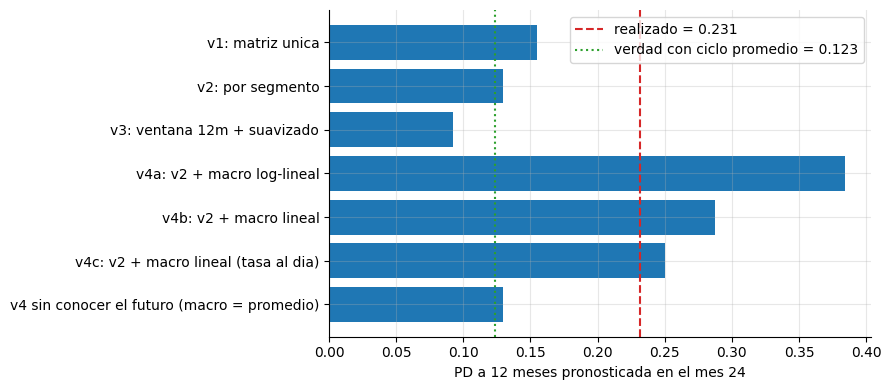

Lectura:
  v1 queda a 0.077 de lo realizado y v2 a 0.102.
  Pero respecto a la verdad con ciclo promedio, v1 se desvia +25% y v2 +5%.
  => v1 se acerca a lo realizado por COMPENSACION: su sesgo por heterogeneidad (al alza) tapa parte de lo que omite del ciclo.
  v3 usa los meses 12-23, cuyo choque medio es -0.16 (vs -0.00 en toda la ventana): una ventana 'reciente' puede ser una fase benigna del ciclo.
  v4a (log-lineal, tasa agregada) +66% | v4b (lineal, tasa agregada) +24% | v4c (lineal, tasa de cuentas al dia) +8% respecto de lo realizado.
  La sensibilidad estimada con la tasa agregada es b=1.38; con la tasa de composicion fija, b=1.09 (verdadero: 1.00).


In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
k = list(cmp_.index)
ax.barh(k, cmp_["PD12"], color="C0")
ax.axvline(real_global, color="C3", ls="--", label=f"realizado = {real_global:.3f}")
ax.axvline(ref_ciclo_prom, color="C2", ls=":", label=f"verdad con ciclo promedio = {ref_ciclo_prom:.3f}")
ax.set_xlabel("PD a 12 meses pronosticada en el mes 24"); ax.legend(); ax.invert_yaxis(); plt.tight_layout(); plt.show()

print("Lectura:")
print(f"  v1 queda a {abs(cmp_.loc['v1: matriz unica', 'PD12'] - real_global):.3f} de lo realizado y v2 a {abs(cmp_.loc['v2: por segmento', 'PD12'] - real_global):.3f}.")
print(f"  Pero respecto a la verdad con ciclo promedio, v1 se desvia {cmp_.loc['v1: matriz unica', 'error_de_especificacion_%']:+.0f}% y v2 {cmp_.loc['v2: por segmento', 'error_de_especificacion_%']:+.0f}%.")
print("  => v1 se acerca a lo realizado por COMPENSACION: su sesgo por heterogeneidad (al alza) tapa parte de lo que omite del ciclo.")
mean_win = choque[T_TRAIN - 12:T_TRAIN].mean()
print(f"  v3 usa los meses 12-23, cuyo choque medio es {mean_win:+.2f} (vs {choque_prom:+.2f} en toda la ventana): una ventana 'reciente' puede ser una fase benigna del ciclo.")
print(f"  v4a (log-lineal, tasa agregada) {cmp_.loc['v4a: v2 + macro log-lineal', 'error_vs_realizado_%']:+.0f}% | v4b (lineal, tasa agregada) {cmp_.loc['v4b: v2 + macro lineal', 'error_vs_realizado_%']:+.0f}% | v4c (lineal, tasa de cuentas al dia) {cmp_.loc['v4c: v2 + macro lineal (tasa al dia)', 'error_vs_realizado_%']:+.0f}% respecto de lo realizado.")
print(f"  La sensibilidad estimada con la tasa agregada es b={b_lin:.2f}; con la tasa de composicion fija, b={b_lin0:.2f} (verdadero: 1.00).")

**Qué se aprende**

1. Las matrices estimadas con el pasado solo reproducen el pasado: ninguna versión que ignore el ciclo anticipa el deterioro posterior.
2. **Comparar solo contra lo realizado puede premiar al peor modelo** si sus errores se compensan. La referencia correcta separa especificación de ciclo.
3. **Reciente no siempre es mejor:** la ventana corta solo ayuda si el futuro se parece a esa fase del ciclo.
4. Un ajuste macro **extrapolado fuera del rango de entrenamiento** depende de dos decisiones que el R² dentro de la muestra no distingue: la **forma funcional** (log-lineal vs lineal) y **qué tasa se regresa** (agregada vs de composición fija). Un R² parecido puede esconder pronósticos muy distintos.
5. La memoria de segundo orden es estadísticamente detectable, pero su efecto sobre la PD a 12 meses es pequeño; detectar no es lo mismo que importar.

## 8. Robustez: suavizado en muestras pequeñas

In [17]:
# ¿Cuando ayuda el suavizado? Se compara el error de la matriz estimada vs la verdadera con distinta cantidad de datos.
P_obj = escalar(BASE["subprime"], 1)
P_prior = P_ver                                            # prior deliberadamente imperfecta: la mezcla de segmentos
rng_s = np.random.default_rng(3)

def error_filas(Phat, Ptrue, filas=(1, 2, 3)):
    return np.mean([np.abs(Phat[i] - Ptrue[i]).sum() for i in filas])

res = []
for n_cuentas in (150, 400, 1500, 6000):
    e_mle, e_sua = [], []
    for _ in range(80):
        pan = simular_homogeneo(P_obj, n_cuentas, 12, rng_s)
        n_ = conteos(pan, t0=0, t1=12)
        e_mle.append(error_filas(mle(n_), P_obj))
        sm = (n_ + kappa * P_prior) / (n_.sum(axis=1, keepdims=True) + kappa)
        e_sua.append(error_filas(sm, P_obj))
    res.append({"cuentas": n_cuentas, "error_MLE": np.mean(e_mle), "error_suavizado": np.mean(e_sua)})
suav = pd.DataFrame(res).set_index("cuentas"); suav["mejora_%"] = (1 - suav["error_suavizado"] / suav["error_MLE"]) * 100
suav.round(4)

,error_MLE,error_suavizado,mejora_%
cuentas,,,
150,0.1163,0.0860,26.0033
400,0.0754,0.0638,15.3250
1500,0.0373,0.0357,4.3823
6000,0.0197,0.0194,1.6677


In [18]:
print("Lectura:")
print(f"  Con {suav.index[0]} cuentas el suavizado cambia el error en {suav['mejora_%'].iloc[0]:+.0f}%; con {suav.index[-1]} cuentas, en {suav['mejora_%'].iloc[-1]:+.0f}%.")
print("  La ventaja del suavizado se concentra en muestras pequenas y se diluye al crecer la muestra. La prior usada aqui es deliberadamente imperfecta (la mezcla de segmentos) y aun asi ayuda en este rango; con una prior peor, o muestras mucho mayores, el sesgo de la prior podria superar su beneficio.")

Lectura:
  Con 150 cuentas el suavizado cambia el error en +26%; con 6000 cuentas, en +2%.
  La ventaja del suavizado se concentra en muestras pequenas y se diluye al crecer la muestra. La prior usada aqui es deliberadamente imperfecta (la mezcla de segmentos) y aun asi ayuda en este rango; con una prior peor, o muestras mucho mayores, el sesgo de la prior podria superar su beneficio.


## 9. Pruebas automáticas

In [19]:
# 9.1 propiedades de una matriz estocastica
for nombre, M in (("P1", P1), ("P2_prime", P2[0]), ("P2_sub", P2[1]), ("P3_prime", P3[0]), ("P3_sub", P3[1])):
    assert np.allclose(M.sum(axis=1), 1), f"{nombre}: filas no suman 1"
    assert (M >= 0).all(), f"{nombre}: probabilidades negativas"
    assert np.allclose(M[4], [0, 0, 0, 0, 1]), f"{nombre}: default debe ser absorbente"
# 9.2 la PD crece con el horizonte y esta en [0,1]
horizontes = [matrix_power(P1, h)[0, 4] for h in range(1, 25)]
assert np.all(np.diff(horizontes) >= 0) and 0 <= horizontes[0] <= horizontes[-1] <= 1
# 9.3 el MLE recupera la matriz en un mundo homogeneo con muestra grande
pan_g = simular_homogeneo(P_ver, 80_000, 12, np.random.default_rng(9))
assert np.abs(mle(conteos(pan_g, t0=0, t1=12)) - P_ver).max() < 0.012
# 9.4 el IC bootstrap cubre aproximadamente el nivel nominal cuando el modelo es correcto
assert 0.85 <= cobertura <= 1.0, f"cobertura fuera de rango: {cobertura}"
# 9.5 el panel real rechaza homogeneidad entre segmentos y la propiedad de Markov
assert (het["p_valor"] < 0.01).all() and p_mem < 0.01
# 9.6 con una prior fuerte y pocos datos el suavizado reduce el error; con muchos datos la ventaja se reduce
assert suav["mejora_%"].iloc[0] > 0 and suav["mejora_%"].iloc[0] > suav["mejora_%"].iloc[-1]
# 9.7 el modelo por segmento estima mejor la estructura que la matriz unica (referencia: verdad con ciclo promedio)
assert abs(cmp_.loc["v2: por segmento", "error_de_especificacion_%"]) < abs(cmp_.loc["v1: matriz unica", "error_de_especificacion_%"]), "v2 debe estar mas cerca de la verdad estructural"
# 9.7b ninguna version sin ciclo anticipa el deterioro
for k_ in ("v1: matriz unica", "v2: por segmento", "v3: ventana 12m + suavizado", "v4 sin conocer el futuro (macro = promedio)"):
    assert cmp_.loc[k_, "PD12"] < real_global, f"{k_} deberia quedar por debajo de lo realizado"
# 9.7c la ventana reciente fue una fase benigna y empeoro el pronostico; el ajuste macro lineal mejora, el log-lineal sobrerreacciona
assert choque[T_TRAIN - 12:T_TRAIN].mean() < choque[:T_TRAIN].mean()
assert abs(cmp_.loc["v3: ventana 12m + suavizado", "error_vs_realizado_%"]) > abs(cmp_.loc["v2: por segmento", "error_vs_realizado_%"])
assert abs(cmp_.loc["v4b: v2 + macro lineal", "error_vs_realizado_%"]) < abs(cmp_.loc["v2: por segmento", "error_vs_realizado_%"])
assert cmp_.loc["v4a: v2 + macro log-lineal", "error_vs_realizado_%"] > cmp_.loc["v4b: v2 + macro lineal", "error_vs_realizado_%"] > 0, "log-lineal sobrerreacciona mas que lineal"
assert abs(b_lin0 - 1) < abs(b_lin - 1), "la tasa de composicion fija debe estimar mejor la sensibilidad"
assert abs(cmp_.loc["v4c: v2 + macro lineal (tasa al dia)", "error_vs_realizado_%"]) < abs(cmp_.loc["v4b: v2 + macro lineal", "error_vs_realizado_%"])
# 9.7d el efecto de la memoria sobre la PD12 es pequeno
assert abs(ref_ciclo_real / real_global - 1) < 0.05
# 9.8 la escala por defecto 1 deja la matriz intacta; escalar es monotono en el riesgo
assert np.allclose(escalar(BASE["prime"], 1), BASE["prime"]) and pd12(escalar(BASE["prime"], 1.5)) > pd12(escalar(BASE["prime"], 1.0))
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: matriz única | El IC95% cubre cuando el modelo es correcto, pero la matriz mezcla segmentos | El IC mide solo ruido de muestreo, no sesgo de especificación |
| Diagnóstico | Se rechaza homogeneidad entre segmentos y la propiedad de Markov | Segmentar; recordar que detectar memoria no implica que importe |
| v2 vs v1 | v1 parece más cercana a lo realizado por compensación de errores; v2 estima mejor la estructura | Comparar contra la referencia correcta, no solo contra lo realizado |
| v3: ventana reciente | La ventana de 12 meses cayó en una fase benigna del ciclo y empeoró el pronóstico | Reciente solo ayuda si el futuro se parece a esa fase |
| v4: indicador macro | Condicionar al ciclo acerca el pronóstico, pero la sensibilidad estimada con una tasa agregada se sobreestima (efecto de composición) y la forma log-lineal extrapola peor | Estimar la sensibilidad con tasas de composición fija y probar formas funcionales |

**Límites que no deben ocultarse**

- El ciclo y la memoria se diseñaron para este ejercicio; en una cartera real hay que identificarlos con datos y juicio.
- La forma lineal es la verdadera en este generador; con otra verdad la elección correcta podría ser otra. Dentro del entrenamiento las formas tienen R² similares, así que los datos no deciden.
- El indicador macro observado es casi la verdad con ruido pequeño; con un indicador más débil la mejora sería menor.
- La prueba de memoria solo mira un par de estados; una verificación completa de Markov es más amplia.
- Los datos son sintéticos: las magnitudes de error no son extrapolables a una cartera real.